In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, EfficientNetB0
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_preprocess
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

Check Where Your Images Actually Are

In [2]:
import os

# List what's actually in your Kaggle dataset — run this FIRST to find the correct paths
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname, len(filenames), "files")

/kaggle/input 0 files
/kaggle/input/datasets 0 files
/kaggle/input/datasets/emansampangrai 0 files
/kaggle/input/datasets/emansampangrai/image0 0 files
/kaggle/input/datasets/emansampangrai/image0/dataset 3 files
/kaggle/input/datasets/emansampangrai/image0/dataset/test 2056 files
/kaggle/input/datasets/emansampangrai/image0/dataset/train 8227 files


# Load the CSV  

In [3]:
train_df = pd.read_csv('/kaggle/input/datasets/emansampangrai/image0/dataset/train.csv')
test_df = pd.read_csv('/kaggle/input/datasets/emansampangrai/image0/dataset/test.csv')

value_counts() shows how many images per sport — useful to know if some classes have far fewer images (imbalance affects accuracy).

In [4]:
TRAIN_DIR = '/kaggle/input/datasets/emansampangrai/image0/dataset/train 8227 files'   # update to your actual path
TEST_DIR = '/kaggle/input/datasets/emansampangrai/image0/dataset/test 2056 files'

print(train_df.head())

         image_ID      label
0  7c225f7b61.jpg  Badminton
1         b31.jpg  Badminton
2  acb146546c.jpg  Badminton
3  0e62f4d8f2.jpg  Badminton
4  cfd2c28c74.jpg    Cricket


In [5]:
TRAIN_DIR = '/kaggle/input/datasets/emansampangrai/image0/dataset/train/'
TEST_DIR = '/kaggle/input/datasets/emansampangrai/image0/dataset/test/'

print(TRAIN_DIR)   # sanity check — should print ONLY the path, nothing else

/kaggle/input/datasets/emansampangrai/image0/dataset/train/


In [6]:
import os

files_in_folder = os.listdir(TRAIN_DIR)
print("Number of files:", len(files_in_folder))
print("First 5 actual files:", files_in_folder[:5])
print("First 5 CSV filenames:", train_df['image_ID'].head().tolist())

Number of files: 8227
First 5 actual files: ['5fbb02e5db.jpg', 'de9ea80624.jpg', '7877d838bc.jpg', '07f2d4156d.jpg', 'e0e698bb5f.jpg']
First 5 CSV filenames: ['7c225f7b61.jpg', 'b31.jpg', 'acb146546c.jpg', '0e62f4d8f2.jpg', 'cfd2c28c74.jpg']


# Split Train Data into Train + Validation

In [7]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    train_df, test_size=0.2, random_state=42, stratify=train_df['label']
)

print("Train size:", train_data.shape)
print("Validation size:", val_data.shape)

Train size: (6581, 2)
Validation size: (1646, 2)


# Import Libraries for Image Preprocessing

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_prep
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_prep

# Set Image Size and Batch Size

In [9]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Function to Build Generators (Reusable for Both Models)

In [10]:
def make_generators(preprocess_func):
    train_gen = ImageDataGenerator(
        preprocessing_function=preprocess_func,
        rotation_range=15,
        zoom_range=0.15,
        horizontal_flip=True
    )
    val_gen = ImageDataGenerator(preprocessing_function=preprocess_func)

    train_flow = train_gen.flow_from_dataframe(
        dataframe=train_data,
        directory=TRAIN_DIR,
        x_col='image_ID',
        y_col='label',
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=True
    )

    val_flow = val_gen.flow_from_dataframe(
        dataframe=val_data,
        directory=TRAIN_DIR,
        x_col='image_ID',
        y_col='label',
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=False
    )

    return train_flow, val_flow

# Create Generators for VGG16

In [11]:
train_vgg, val_vgg = make_generators(vgg_prep)

Found 6581 validated image filenames belonging to 7 classes.
Found 1646 validated image filenames belonging to 7 classes.


# Import Libraries for Building the Model

In [12]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Function to Build a Model (Reusable for VGG16 and EfficientNet)

In [13]:
NUM_CLASSES = train_df['label'].nunique()

def build_model(base_model):
    base_model.trainable = False   # freeze the pretrained layers first

    x = GlobalAveragePooling2D()(base_model.output)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.5)(x)
    output = Dense(NUM_CLASSES, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.0001),
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])
    return model

# Build and Train VGG16

In [14]:
vgg_base = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
vgg_model = build_model(vgg_base)

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

vgg_model.fit(
    train_vgg,
    validation_data=val_vgg,
    epochs=10,
    callbacks=[early_stop]
)

I0000 00:00:1788608555.102994      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788608555.106195      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
  1/206 ━━━━━━━━━━━━━━━━━━━━ 53:52 16s/step - accuracy: 0.1562 - loss: 9.8880

I0000 00:00:1788608574.649066      69 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


206/206 ━━━━━━━━━━━━━━━━━━━━ 161s 707ms/step - accuracy: 0.2693 - loss: 5.1444 - val_accuracy: 0.5158 - val_loss: 1.8173
Epoch 2/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 104s 504ms/step - accuracy: 0.4182 - loss: 2.2332 - val_accuracy: 0.6069 - val_loss: 1.2053
Epoch 3/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 103s 497ms/step - accuracy: 0.4846 - loss: 1.5938 - val_accuracy: 0.6598 - val_loss: 1.0171
Epoch 4/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 104s 504ms/step - accuracy: 0.5413 - loss: 1.3375 - val_accuracy: 0.7023 - val_loss: 0.8937
Epoch 5/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 103s 502ms/step - accuracy: 0.5853 - loss: 1.2159 - val_accuracy: 0.7248 - val_loss: 0.8061
Epoch 6/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 105s 509ms/step - accuracy: 0.6206 - loss: 1.0818 - val_accuracy: 0.7442 - val_loss: 0.7426
Epoch 7/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 104s 503ms/step - accuracy: 0.6511 - loss: 0.9983 - val_accuracy: 0.7734 - val_loss: 0.6770
Epoch 8/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 104s 503ms/step - accuracy: 0.6701 - loss: 0.92

Epoch 1/10: accuracy: 0.2743 → Epoch 10/10: accuracy: 0.8177
val_accuracy: 0.5170 → val_accuracy: (continuing to improve across epochs, likely similar trend)

# Check VGG16's Final Validation Accuracy

In [15]:
vgg_loss, vgg_acc = vgg_model.evaluate(val_vgg)
print("VGG16 Validation Accuracy:", vgg_acc)

52/52 ━━━━━━━━━━━━━━━━━━━━ 9s 174ms/step - accuracy: 0.8086 - loss: 0.5690
VGG16 Validation Accuracy: 0.8086269497871399


# EfficientNet

# Import EfficientNet

In [16]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_prep

# Create Generators for EfficientNet

In [17]:
train_eff, val_eff = make_generators(eff_prep)

Found 6581 validated image filenames belonging to 7 classes.
Found 1646 validated image filenames belonging to 7 classes.


# Build and Train EfficientNet

In [18]:
eff_base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
eff_model = build_model(eff_base)

eff_model.fit(
    train_eff,
    validation_data=val_eff,
    epochs=10,
    callbacks=[early_stop]
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10


2026-09-05 12:01:29.379087: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:01:29.523676: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:01:29.885069: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:01:30.027231: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:01:30.857556: E external/local_xla/xla/stream_

  1/206 ━━━━━━━━━━━━━━━━━━━━ 1:34:23 28s/step - accuracy: 0.0625 - loss: 2.1361

2026-09-05 12:01:45.614577: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:01:45.756695: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:01:46.096322: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:01:46.238971: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:01:47.067066: E external/local_xla/xla/stream_

206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 520ms/step - accuracy: 0.3796 - loss: 1.6402

2026-09-05 12:03:45.462352: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:03:45.601738: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:03:45.927292: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:03:46.069127: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:03:46.216541: E external/local_xla/xla/stream_

206/206 ━━━━━━━━━━━━━━━━━━━━ 160s 648ms/step - accuracy: 0.5385 - loss: 1.3275 - val_accuracy: 0.8341 - val_loss: 0.6974
Epoch 2/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 100s 484ms/step - accuracy: 0.7841 - loss: 0.7028 - val_accuracy: 0.8955 - val_loss: 0.4242
Epoch 3/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 97s 469ms/step - accuracy: 0.8392 - loss: 0.5147 - val_accuracy: 0.9156 - val_loss: 0.3298
Epoch 4/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 95s 461ms/step - accuracy: 0.8608 - loss: 0.4429 - val_accuracy: 0.9228 - val_loss: 0.2809
Epoch 5/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 96s 466ms/step - accuracy: 0.8752 - loss: 0.3949 - val_accuracy: 0.9295 - val_loss: 0.2489
Epoch 6/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 96s 465ms/step - accuracy: 0.8891 - loss: 0.3506 - val_accuracy: 0.9386 - val_loss: 0.2329
Epoch 7/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 95s 461ms/step - accuracy: 0.8999 - loss: 0.3174 - val_accuracy: 0.9405 - val_loss: 0.2125
Epoch 8/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 98s 474ms/step - accuracy: 0.9049 - loss: 0.2933 - v

# Check EfficientNet's Final Accuracy

In [19]:
eff_loss, eff_acc = eff_model.evaluate(val_eff)
print("EfficientNet Validation Accuracy:", eff_acc)

52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 144ms/step - accuracy: 0.9532 - loss: 0.1808
EfficientNet Validation Accuracy: 0.9532199501991272


VGG16 Validation Accuracy:        0.8098  
EfficientNet Validation Accuracy: 0.9453  

EfficientNet is a newer, more efficient architecture — it was specifically designed to scale depth, width, and resolution together in a balanced way, extracting more useful features per parameter than VGG16's older, simpler stacked-convolution design (the VGG-16 diagram we looked at way back is a much older)

52/52 ━━━━━━━━━━━━━━━━━━━━ 20s 266ms/step


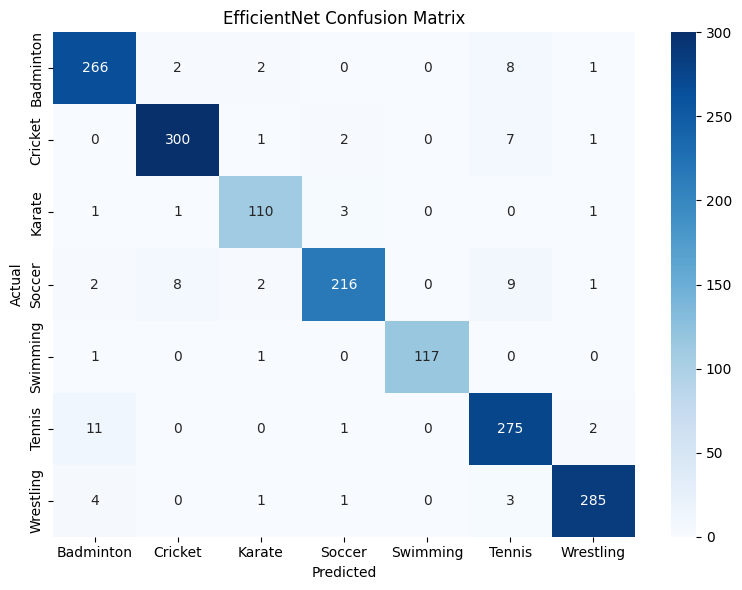

              precision    recall  f1-score   support

   Badminton       0.93      0.95      0.94       279
     Cricket       0.96      0.96      0.96       311
      Karate       0.94      0.95      0.94       116
      Soccer       0.97      0.91      0.94       238
    Swimming       1.00      0.98      0.99       119
      Tennis       0.91      0.95      0.93       289
   Wrestling       0.98      0.97      0.97       294

    accuracy                           0.95      1646
   macro avg       0.96      0.95      0.96      1646
weighted avg       0.95      0.95      0.95      1646



In [20]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

val_eff.reset()
val_preds = eff_model.predict(val_eff)
val_pred_classes = np.argmax(val_preds, axis=1)
val_true_classes = val_eff.classes
class_labels = list(val_eff.class_indices.keys())

cm = confusion_matrix(val_true_classes, val_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('EfficientNet Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

print(classification_report(val_true_classes, val_pred_classes, target_names=class_labels))

EfficientNet performs strongly and consistently across all 7 sports, with Karate being the only relatively weaker class

# Generate Submission File

In [21]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

test_datagen = ImageDataGenerator(preprocessing_function=eff_prep)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    directory=TEST_DIR,
    x_col='image_ID',
    y_col=None,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode=None,
    shuffle=False
)

predictions = eff_model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)

label_map = {v: k for k, v in train_eff.class_indices.items()}
predicted_labels = [label_map[i] for i in predicted_classes]

submission = pd.DataFrame({'image_ID': test_df['image_ID'], 'label': predicted_labels})
submission.to_csv('submission.csv', index=False)
print(submission.head())

Found 2056 validated image filenames.
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step

2026-09-05 12:19:27.127080: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:19:27.264305: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:19:27.578834: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:19:27.720996: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-05 12:19:28.480019: E external/local_xla/xla/stream_

65/65 ━━━━━━━━━━━━━━━━━━━━ 34s 431ms/step
         image_ID      label
0  f5e13966e7.jpg     Soccer
1  6674191b4e.jpg  Badminton
2  91b5f8b7a9.jpg  Badminton
3  393119b6d6.jpg  Wrestling
4  1ce5f81578.jpg     Tennis
